### Univariate Analysis

#### Keith R. Holdaway FGS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Generate synthetic well log data
np.random.seed(42)
data = {
    'GR': np.random.normal(60, 15, 1000),  # Gamma Ray (API)
    'NPHI': np.random.uniform(0.1, 0.3, 1000),  # Neutron Porosity (v/v)
    'RHOB': np.random.normal(2.4, 0.1, 1000),  # Bulk Density (g/cc)
    'Facies': np.random.choice(['Sandstone', 'Shale', 'Limestone'], size=1000)
}
df = pd.DataFrame(data)

## Box Plots (Numerical Variables)

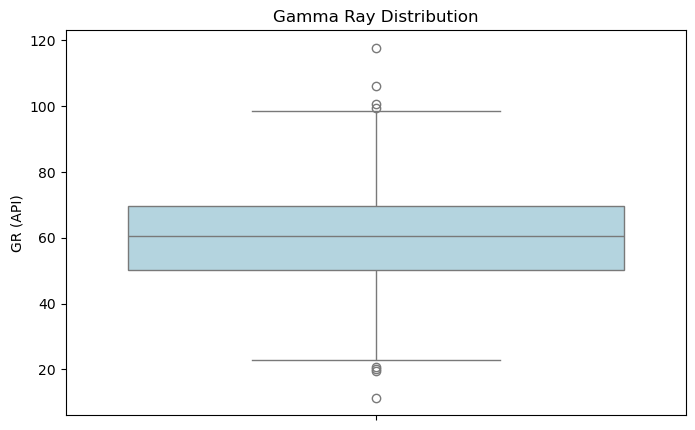

In [2]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y='GR', color='lightblue')
plt.title('Gamma Ray Distribution')
plt.ylabel('GR (API)')
plt.show()

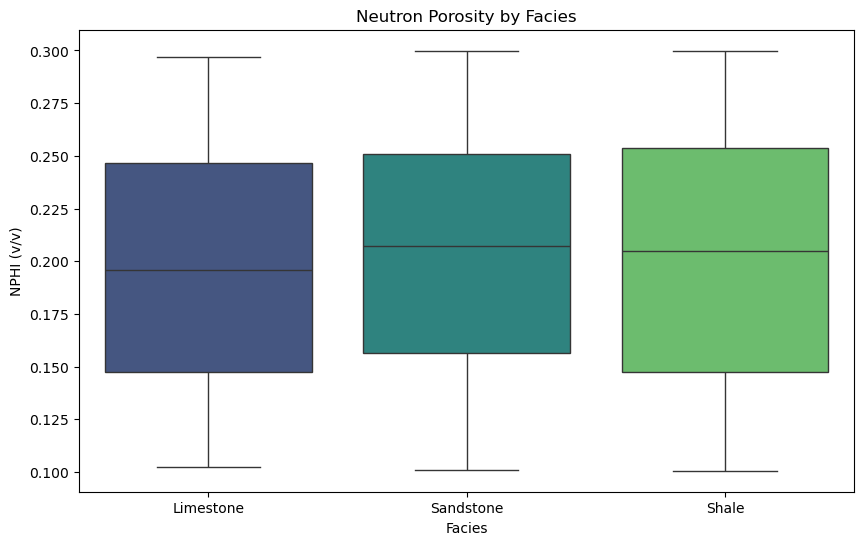

In [3]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Facies', y='NPHI', palette='viridis', hue='Facies', legend=False)
plt.title('Neutron Porosity by Facies')
plt.xlabel('Facies')
plt.ylabel('NPHI (v/v)')
plt.show()

## Histograms (Distribution Visualization)

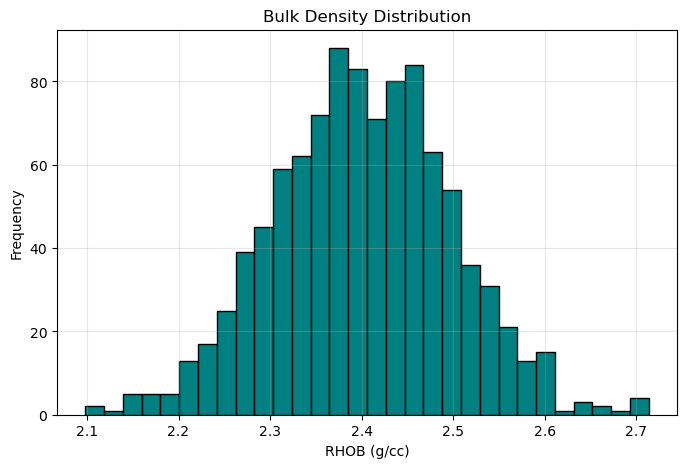

In [4]:
plt.figure(figsize=(8, 5))
plt.hist(df['RHOB'], bins=30, color='teal', edgecolor='black')
plt.title('Bulk Density Distribution')
plt.xlabel('RHOB (g/cc)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

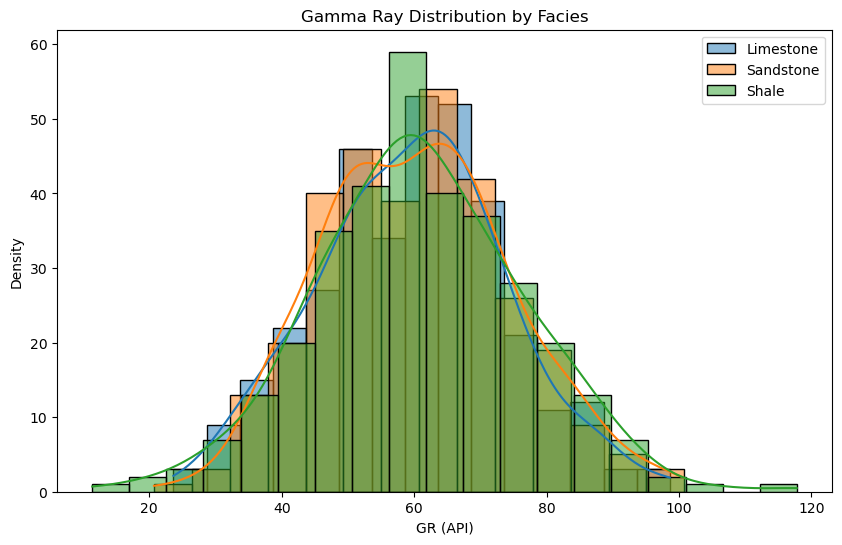

In [5]:
plt.figure(figsize=(10, 6))
for facies in df['Facies'].unique():
    sns.histplot(data=df[df['Facies'] == facies], x='GR', 
                 kde=True, label=facies, alpha=0.5)
plt.title('Gamma Ray Distribution by Facies')
plt.xlabel('GR (API)')
plt.ylabel('Density')
plt.legend()
plt.show()

## Combined Box Plot + Histogram

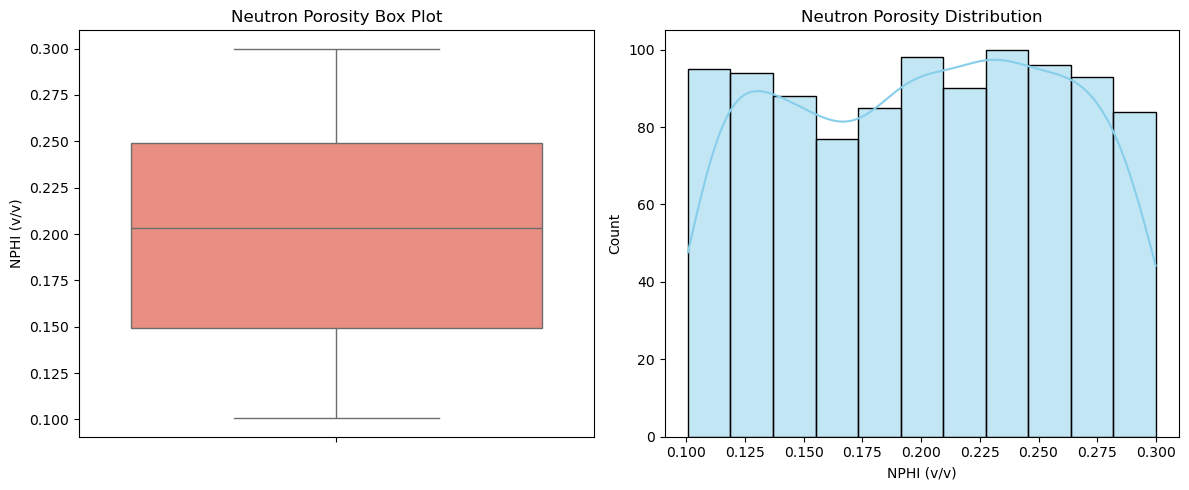

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Box plot
sns.boxplot(data=df, y='NPHI', ax=ax1, color='salmon')
ax1.set_ylabel('NPHI (v/v)')
ax1.set_title('Neutron Porosity Box Plot')

# Histogram
sns.histplot(data=df, x='NPHI', kde=True, ax=ax2, color='skyblue')
ax2.set_xlabel('NPHI (v/v)')
ax2.set_title('Neutron Porosity Distribution')

plt.tight_layout()
plt.show()

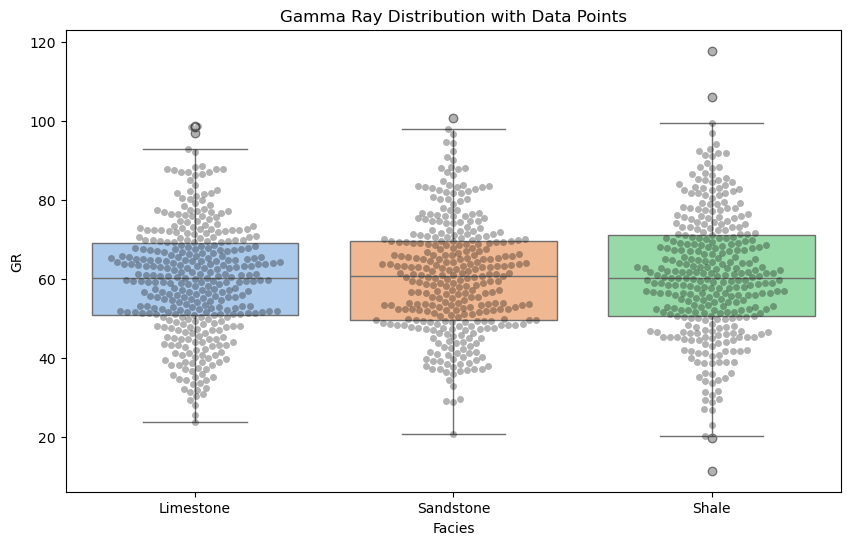

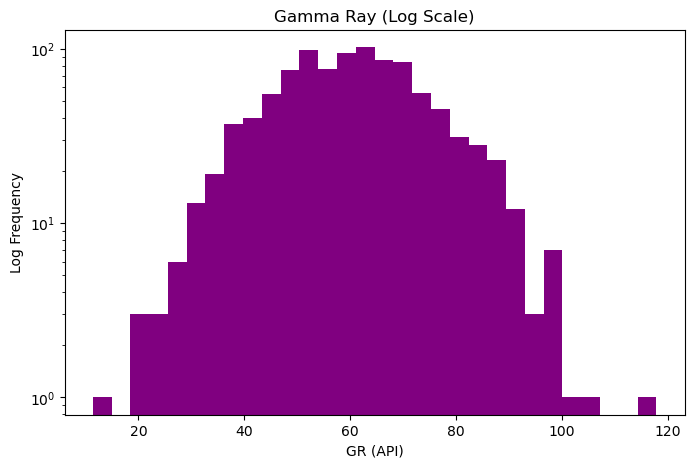

In [7]:
# Enhanced box plot with swarmplot overlay
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=df, x='Facies', y='GR', palette='pastel', hue='Facies', legend=False)
sns.swarmplot(data=df, x='Facies', y='GR', color='black', alpha=0.3, ax=ax)
plt.title('Gamma Ray Distribution with Data Points')
plt.show()

# Log-scale histogram for skewed data
plt.figure(figsize=(8, 5))
plt.hist(df['GR'], bins=30, color='purple', log=True)
plt.title('Gamma Ray (Log Scale)')
plt.xlabel('GR (API)')
plt.ylabel('Log Frequency')
plt.show()

# Practical Petrophysics Applications
## Identify Outliers in Log Measurements:

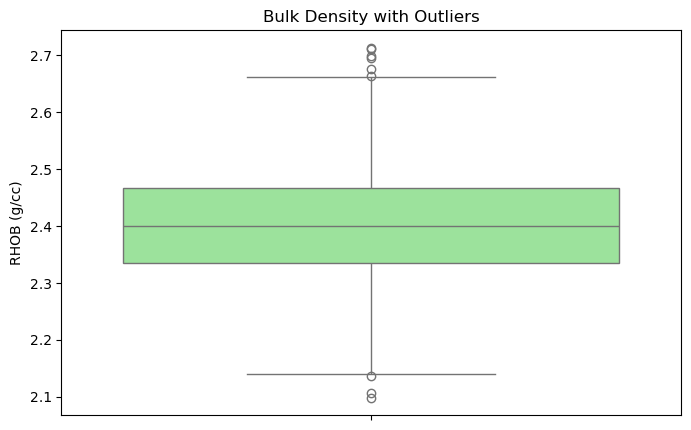

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y='RHOB', showfliers=True, color='lightgreen')
plt.title('Bulk Density with Outliers')
plt.ylabel('RHOB (g/cc)')
plt.show()

# Compare Reservoir vs Non-Reservoir Zones:

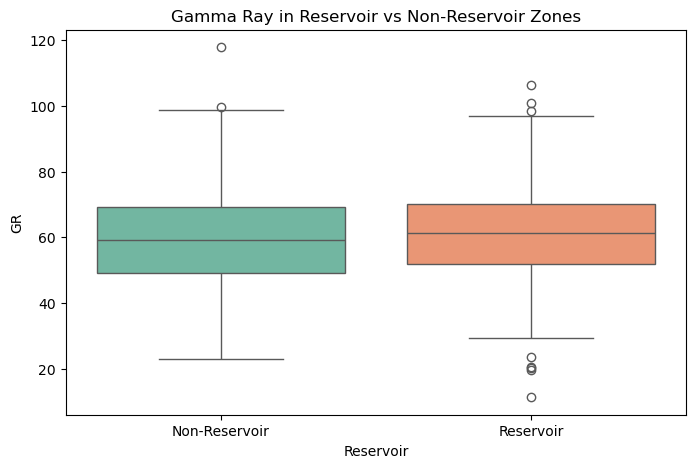

In [9]:
df['Reservoir'] = np.where(df['NPHI'] > 0.2, 'Reservoir', 'Non-Reservoir')
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Reservoir', y='GR', palette='Set2', hue='Reservoir', legend=False)
plt.title('Gamma Ray in Reservoir vs Non-Reservoir Zones')
plt.show()